In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/phishing url project/PhiUSIIL_Phishing_URL_Dataset.csv")

df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [ ]:
df.shape

(235795, 56)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

In [ ]:
df.describe()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,...,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516,0.571895
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,...,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430,0.494805
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000,1.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,...,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000,1.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


In [ ]:
df.isnull().sum()

,0
FILENAME,0
URL,0
URLLength,0
Domain,0
DomainLength,0
IsDomainIP,0
TLD,0
URLSimilarityIndex,0
CharContinuationRate,0
TLDLegitimateProb,0


In [ ]:
df['label'].value_counts()

,count
label,
1,134850
0,100945


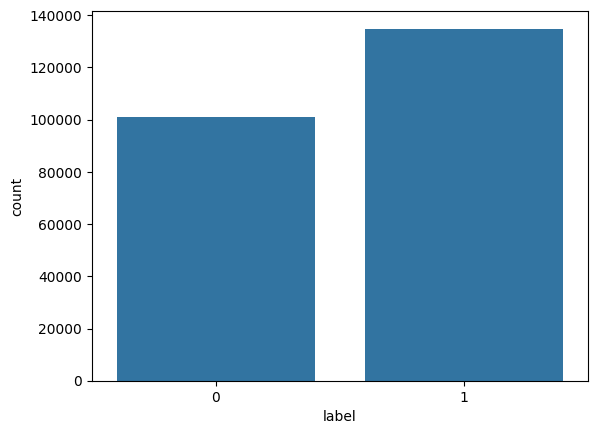

In [ ]:
sns.countplot(x='label', data=df)
plt.show()

In [ ]:
#df['IsDomainIP'].value_counts()

#df['HasObfuscation'].value_counts()

#df['NoOfObfuscatedChar'].value_counts()

#df['ObfuscationRatio'].value_counts()

#df['NoOfDegitsInURL'].value_counts()

#df['NoOfEqualsInURL'].value_counts()

#df['NoOfQMarkInURL'].value_counts()

#df['NoOfAmpersandInURL'].value_counts()

#df['HasExternalFormSubmit'].value_counts()

#df['Crypto'].value_counts()

#df['Title'].value_counts()

In [ ]:
cols_to_drop = ['FILENAME', 'IsDomainIP','HasObfuscation', 'NoOfObfuscatedChar','ObfuscationRatio', 'NoOfDegitsInURL','NoOfEqualsInURL','NoOfQMarkInURL','NoOfAmpersandInURL','HasExternalFormSubmit','Crypto','Title','Domain']

# Filter list to only columns that exist in df
existing_cols = [col for col in cols_to_drop if col in df.columns]

# Drop those columns
df.drop(columns=existing_cols, inplace=True)

In [ ]:
df.shape

(235795, 43)

In [ ]:
df['TLD'].value_counts()

,count
TLD,
com,112554
org,18793
net,7097
app,6508
uk,6395
...,...
15,1
nr,1
parts,1


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['TLD_encoded'] = le.fit_transform(df['TLD'])


In [ ]:
df = df.drop(columns=['TLD'])

In [ ]:
df.head()

,URL,URLLength,DomainLength,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,NoOfLettersInURL,...,Pay,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,TLD_encoded
0,https://www.southbankmosaics.com,31,24,100.0,1.000000,0.522907,0.061933,3,1,18,...,0,1,34,20,28,119,0,124,1,231
1,https://www.uni-mainz.de,23,16,100.0,0.666667,0.032650,0.050207,2,1,9,...,0,1,50,9,8,39,0,217,1,254
2,https://www.voicefmradio.co.uk,29,22,100.0,0.866667,0.028555,0.064129,2,2,15,...,0,1,10,2,7,42,2,5,1,647
3,https://www.sfnmjournal.com,26,19,100.0,1.000000,0.522907,0.057606,3,1,13,...,1,1,3,27,15,22,1,31,1,231
4,https://www.rewildingargentina.org,33,26,100.0,1.000000,0.079963,0.059441,3,1,20,...,1,1,244,15,34,72,1,85,1,503


In [ ]:
from nltk.tokenize import RegexpTokenizer

tokenizer = RegexpTokenizer(r'[A-Za-z]+')

df.URL[0]

'https://www.southbankmosaics.com'

In [ ]:
tokenizer.tokenize(df.URL[0])

['https', 'www', 'southbankmosaics', 'com']

In [ ]:
df['text_tokenized'] = df.URL.map(lambda t: tokenizer.tokenize(t))

In [ ]:
df.head()

,URL,URLLength,DomainLength,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,NoOfLettersInURL,...,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,TLD_encoded,text_tokenized
0,https://www.southbankmosaics.com,31,24,100.0,1.000000,0.522907,0.061933,3,1,18,...,1,34,20,28,119,0,124,1,231,"[https, www, southbankmosaics, com]"
1,https://www.uni-mainz.de,23,16,100.0,0.666667,0.032650,0.050207,2,1,9,...,1,50,9,8,39,0,217,1,254,"[https, www, uni, mainz, de]"
2,https://www.voicefmradio.co.uk,29,22,100.0,0.866667,0.028555,0.064129,2,2,15,...,1,10,2,7,42,2,5,1,647,"[https, www, voicefmradio, co, uk]"
3,https://www.sfnmjournal.com,26,19,100.0,1.000000,0.522907,0.057606,3,1,13,...,1,3,27,15,22,1,31,1,231,"[https, www, sfnmjournal, com]"
4,https://www.rewildingargentina.org,33,26,100.0,1.000000,0.079963,0.059441,3,1,20,...,1,244,15,34,72,1,85,1,503,"[https, www, rewildingargentina, org]"


In [ ]:
from nltk.stem.snowball import SnowballStemmer

stemmer = SnowballStemmer("english")

df['text_stemmed'] = df['text_tokenized'].map(lambda l: [stemmer.stem(word) for word in l])

In [ ]:
df.head()

,URL,URLLength,DomainLength,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,NoOfLettersInURL,...,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,TLD_encoded,text_tokenized,text_stemmed
0,https://www.southbankmosaics.com,31,24,100.0,1.000000,0.522907,0.061933,3,1,18,...,34,20,28,119,0,124,1,231,"[https, www, southbankmosaics, com]","[https, www, southbankmosa, com]"
1,https://www.uni-mainz.de,23,16,100.0,0.666667,0.032650,0.050207,2,1,9,...,50,9,8,39,0,217,1,254,"[https, www, uni, mainz, de]","[https, www, uni, mainz, de]"
2,https://www.voicefmradio.co.uk,29,22,100.0,0.866667,0.028555,0.064129,2,2,15,...,10,2,7,42,2,5,1,647,"[https, www, voicefmradio, co, uk]","[https, www, voicefmradio, co, uk]"
3,https://www.sfnmjournal.com,26,19,100.0,1.000000,0.522907,0.057606,3,1,13,...,3,27,15,22,1,31,1,231,"[https, www, sfnmjournal, com]","[https, www, sfnmjournal, com]"
4,https://www.rewildingargentina.org,33,26,100.0,1.000000,0.079963,0.059441,3,1,20,...,244,15,34,72,1,85,1,503,"[https, www, rewildingargentina, org]","[https, www, rewildingargentina, org]"


In [ ]:
df['text'] = df['text_stemmed'].map(lambda l: ' '.join(l))

In [ ]:
df.head()

,URL,URLLength,DomainLength,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,NoOfLettersInURL,...,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,TLD_encoded,text_tokenized,text_stemmed,text
0,https://www.southbankmosaics.com,31,24,100.0,1.000000,0.522907,0.061933,3,1,18,...,20,28,119,0,124,1,231,"[https, www, southbankmosaics, com]","[https, www, southbankmosa, com]",https www southbankmosa com
1,https://www.uni-mainz.de,23,16,100.0,0.666667,0.032650,0.050207,2,1,9,...,9,8,39,0,217,1,254,"[https, www, uni, mainz, de]","[https, www, uni, mainz, de]",https www uni mainz de
2,https://www.voicefmradio.co.uk,29,22,100.0,0.866667,0.028555,0.064129,2,2,15,...,2,7,42,2,5,1,647,"[https, www, voicefmradio, co, uk]","[https, www, voicefmradio, co, uk]",https www voicefmradio co uk
3,https://www.sfnmjournal.com,26,19,100.0,1.000000,0.522907,0.057606,3,1,13,...,27,15,22,1,31,1,231,"[https, www, sfnmjournal, com]","[https, www, sfnmjournal, com]",https www sfnmjournal com
4,https://www.rewildingargentina.org,33,26,100.0,1.000000,0.079963,0.059441,3,1,20,...,15,34,72,1,85,1,503,"[https, www, rewildingargentina, org]","[https, www, rewildingargentina, org]",https www rewildingargentina org


In [ ]:
good_sites = df[df.label == 1]

bad_sites = df[df.label == 0]

In [ ]:
good_sites.head()

,URL,URLLength,DomainLength,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,NoOfLettersInURL,...,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,TLD_encoded,text_tokenized,text_stemmed,text
0,https://www.southbankmosaics.com,31,24,100.0,1.000000,0.522907,0.061933,3,1,18,...,20,28,119,0,124,1,231,"[https, www, southbankmosaics, com]","[https, www, southbankmosa, com]",https www southbankmosa com
1,https://www.uni-mainz.de,23,16,100.0,0.666667,0.032650,0.050207,2,1,9,...,9,8,39,0,217,1,254,"[https, www, uni, mainz, de]","[https, www, uni, mainz, de]",https www uni mainz de
2,https://www.voicefmradio.co.uk,29,22,100.0,0.866667,0.028555,0.064129,2,2,15,...,2,7,42,2,5,1,647,"[https, www, voicefmradio, co, uk]","[https, www, voicefmradio, co, uk]",https www voicefmradio co uk
3,https://www.sfnmjournal.com,26,19,100.0,1.000000,0.522907,0.057606,3,1,13,...,27,15,22,1,31,1,231,"[https, www, sfnmjournal, com]","[https, www, sfnmjournal, com]",https www sfnmjournal com
4,https://www.rewildingargentina.org,33,26,100.0,1.000000,0.079963,0.059441,3,1,20,...,15,34,72,1,85,1,503,"[https, www, rewildingargentina, org]","[https, www, rewildingargentina, org]",https www rewildingargentina org


In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import numpy as np

def plot_wordcloud(text, mask=None, max_words=400, max_font_size=120,
                   figure_size=(24.0, 16.0), title=None, title_size=40,
                   image_color=False):

    # Define stopwords
    stopwords = set(STOPWORDS)
    more_stopwords = {'com', 'http'}
    stopwords = stopwords.union(more_stopwords)

    # Generate wordcloud
    wordcloud = WordCloud(background_color='white',
                          stopwords=stopwords,
                          max_words=max_words,
                          max_font_size=max_font_size,
                          random_state=42,
                          mask=mask)
    wordcloud.generate(text)

    # Plot
    plt.figure(figsize=figure_size)
    if image_color:
        image_colors = ImageColorGenerator(mask)
        plt.imshow(wordcloud.recolor(color_func=image_colors), interpolation="bilinear")
        plt.title(title, fontdict={'size': title_size, 'verticalalignment': 'bottom'})


    else:
        plt.imshow(wordcloud)
        plt.title(title, fontdict={'size': title_size, 'verticalalignment': 'bottom'})


    plt.axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
all_text = ' '.join(good_sites['text'].tolist())

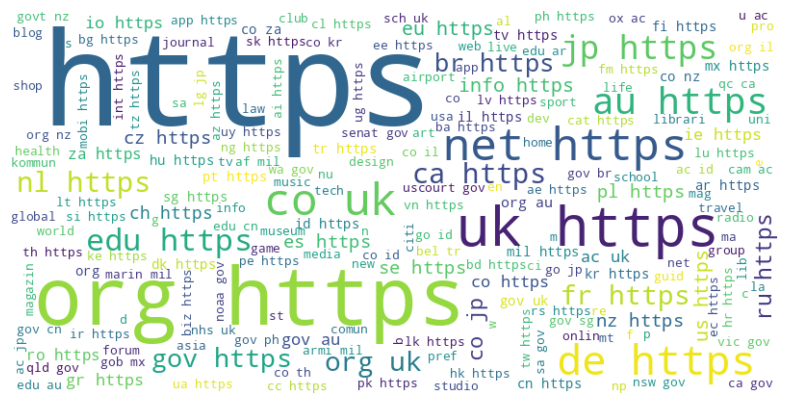

In [ ]:
# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [ ]:
all_text = ' '.join(bad_sites['text'].tolist())

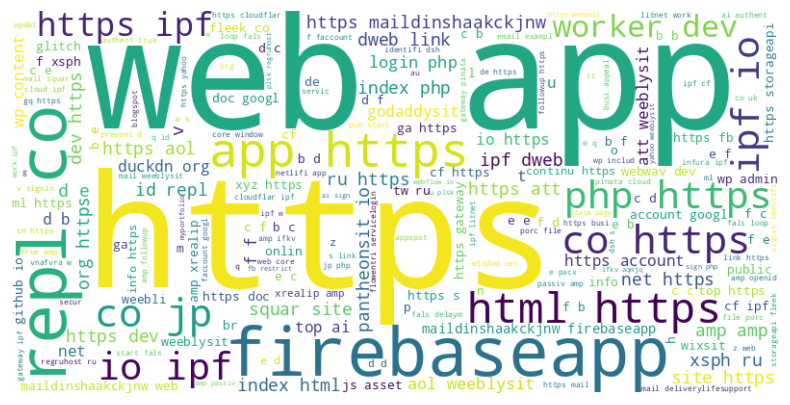

In [ ]:
# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [ ]:
df.head()

,URL,URLLength,DomainLength,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,NoOfLettersInURL,...,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,TLD_encoded,text_tokenized,text_stemmed,text
0,https://www.southbankmosaics.com,31,24,100.0,1.000000,0.522907,0.061933,3,1,18,...,20,28,119,0,124,1,231,"[https, www, southbankmosaics, com]","[https, www, southbankmosa, com]",https www southbankmosa com
1,https://www.uni-mainz.de,23,16,100.0,0.666667,0.032650,0.050207,2,1,9,...,9,8,39,0,217,1,254,"[https, www, uni, mainz, de]","[https, www, uni, mainz, de]",https www uni mainz de
2,https://www.voicefmradio.co.uk,29,22,100.0,0.866667,0.028555,0.064129,2,2,15,...,2,7,42,2,5,1,647,"[https, www, voicefmradio, co, uk]","[https, www, voicefmradio, co, uk]",https www voicefmradio co uk
3,https://www.sfnmjournal.com,26,19,100.0,1.000000,0.522907,0.057606,3,1,13,...,27,15,22,1,31,1,231,"[https, www, sfnmjournal, com]","[https, www, sfnmjournal, com]",https www sfnmjournal com
4,https://www.rewildingargentina.org,33,26,100.0,1.000000,0.079963,0.059441,3,1,20,...,15,34,72,1,85,1,503,"[https, www, rewildingargentina, org]","[https, www, rewildingargentina, org]",https www rewildingargentina org


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(max_features=1000)

features = cv.fit_transform(df.text)

features[:5].toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
from sklearn.preprocessing import StandardScaler

# Let's assume your label column is named 'label'
label_col = 'label'

# Get numeric columns, excluding the label
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop(label_col)

# Initialize the scaler
scaler = StandardScaler()

# Scale only the selected numeric columns
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])


In [ ]:
df.head()

,URL,URLLength,DomainLength,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,NoOfLettersInURL,...,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,TLD_encoded,text_tokenized,text_stemmed,text
0,https://www.southbankmosaics.com,-0.086486,0.276436,0.744382,0.713153,1.043145,0.584293,0.392745,-0.274154,-0.049120,...,0.182551,0.783327,0.305222,-0.134778,0.464130,1,-0.611740,"[https, www, southbankmosaics, com]","[https, www, southbankmosa, com]",https www southbankmosa com
1,https://www.uni-mainz.de,-0.280125,-0.597807,0.744382,-0.825555,-0.905197,-0.523283,-1.274652,-0.274154,-0.358502,...,0.035622,-0.113046,-0.147555,-0.134778,1.041672,1,-0.452746,"[https, www, uni, mainz, de]","[https, www, uni, mainz, de]",https www uni mainz de
2,https://www.voicefmradio.co.uk,-0.134896,0.057875,0.744382,0.097670,-0.921472,0.791672,-1.274652,1.389828,-0.152247,...,-0.057878,-0.157865,-0.130576,-0.021406,-0.274876,1,2.263969,"[https, www, voicefmradio, co, uk]","[https, www, voicefmradio, co, uk]",https www voicefmradio co uk
3,https://www.sfnmjournal.com,-0.207510,-0.269966,0.744382,0.713153,1.043145,0.175546,0.392745,-0.274154,-0.220999,...,0.276051,0.200684,-0.243770,-0.078092,-0.113413,1,-0.611740,"[https, www, sfnmjournal, com]","[https, www, sfnmjournal, com]",https www sfnmjournal com
4,https://www.rewildingargentina.org,-0.038077,0.494997,0.744382,0.713153,-0.717171,0.348931,0.392745,-0.274154,0.019631,...,0.115765,1.052238,0.039216,-0.078092,0.221935,1,1.268532,"[https, www, rewildingargentina, org]","[https, www, rewildingargentina, org]",https www rewildingargentina org


In [ ]:
# Compute correlation matrix
correlation = df.corr(numeric_only=True)

# Show correlation with target only
target_corr = correlation['label'].sort_values(ascending=False)

print(target_corr)

label                         1.000000
URLSimilarityIndex            0.860358
HasSocialNet                  0.784255
HasCopyrightInfo              0.743358
HasDescription                0.690232
IsHTTPS                       0.609132
DomainTitleMatchScore         0.584905
HasSubmitButton               0.578561
IsResponsive                  0.548608
URLTitleMatchScore            0.539419
HasHiddenFields               0.507731
HasFavicon                    0.493711
URLCharProb                   0.469749
CharContinuationRate          0.467735
HasTitle                      0.459725
Robots                        0.392620
NoOfJS                        0.373500
Pay                           0.359747
NoOfSelfRef                   0.316211
NoOfImage                     0.274658
LineOfCode                    0.272257
NoOfExternalRef               0.258627
NoOfiFrame                    0.225822
Bank                          0.188959
HasPasswordField              0.138183
NoOfEmptyRef             

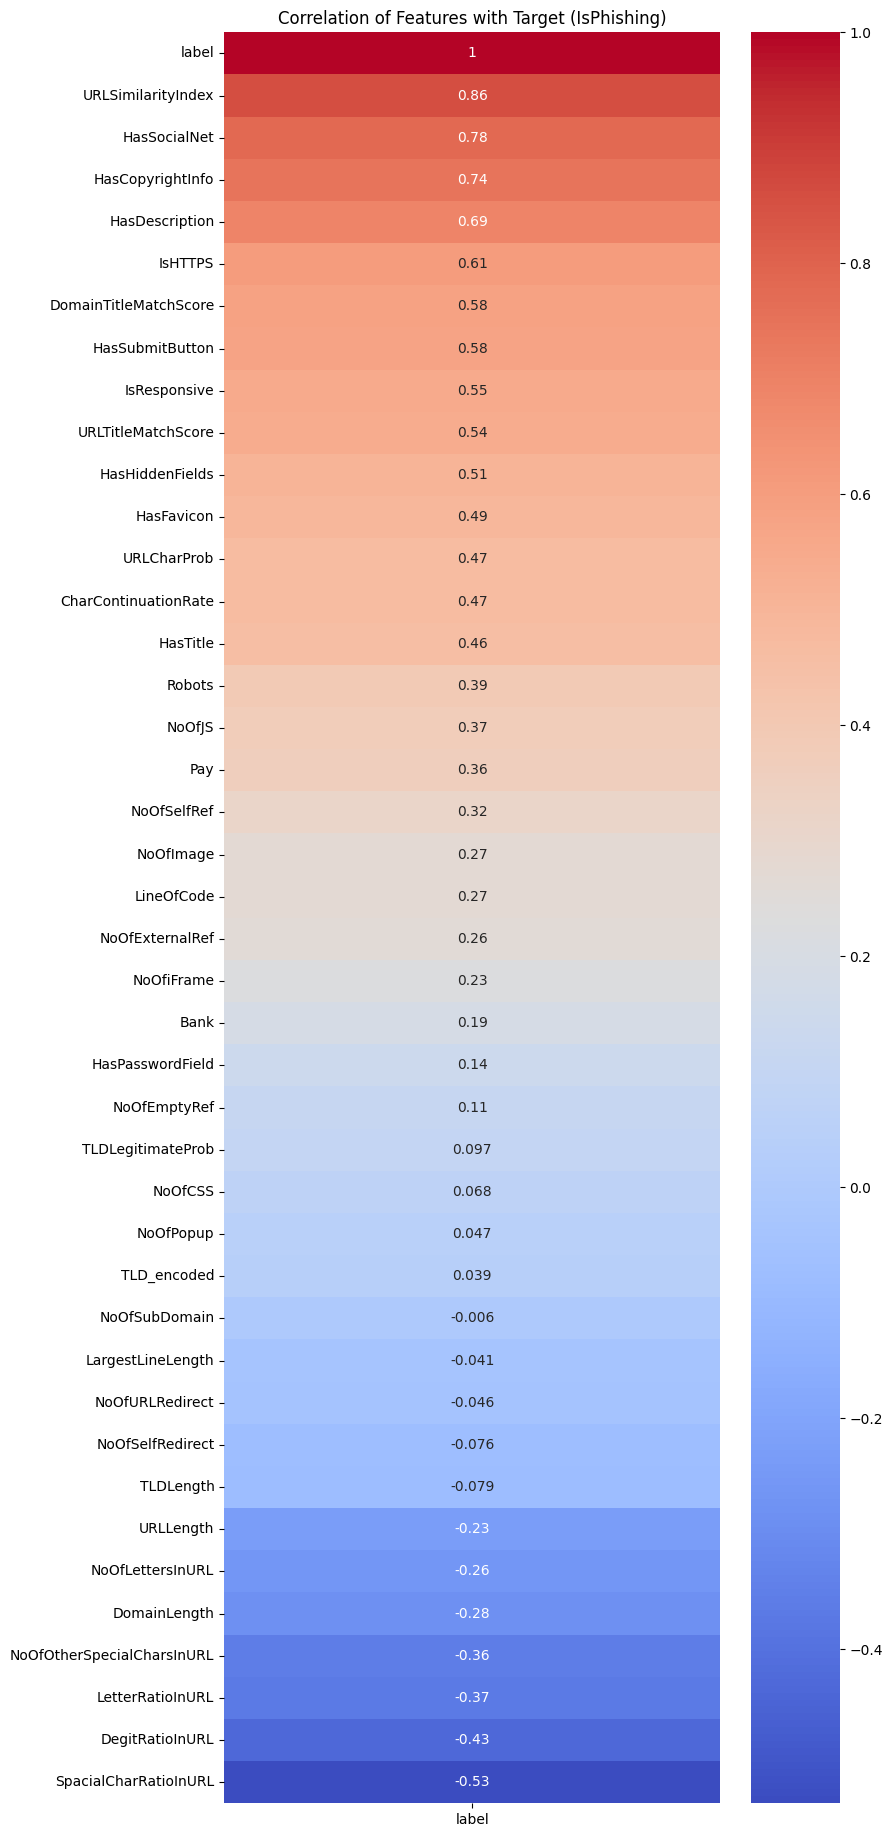

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Only show input features vs target
plt.figure(figsize=(8, len(df.columns) * 0.5))
sns.heatmap(df.corr(numeric_only=True)[['label']].sort_values(by='label', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Correlation of Features with Target (IsPhishing)')
plt.show()

In [ ]:
# Calculate correlation
correlation = df.corr(numeric_only=True)

# Drop columns with very low absolute correlation to target (excluding the target itself)
low_corr_cols = correlation['label'].abs()
low_corr_cols = low_corr_cols[low_corr_cols < 0.05].index.tolist()

# Make sure we don't drop the target column
low_corr_cols = [col for col in low_corr_cols if col != 'label']

# Drop them
df.drop(columns=low_corr_cols, inplace=True)

In [ ]:
print("Dropped low-correlation columns:", low_corr_cols)

Dropped low-correlation columns: ['NoOfSubDomain', 'LargestLineLength', 'NoOfURLRedirect', 'NoOfPopup', 'TLD_encoded']


In [ ]:
df.shape

(235795, 41)

In [ ]:
X = df.drop('label', axis=1)
y = df['label']

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(features, df['label'],stratify = y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


l_model = LogisticRegression()
l_model.fit(x_train, y_train)


LogisticRegression()

In [ ]:
l_model.score(x_train, y_train)

0.9949532432833605

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, accuracy_score

# 1. Choose a model
model = LogisticRegression(max_iter=1000)

# 2. Run cross-validation (e.g., 5-fold)
scores = cross_val_score(model, features, y, cv=5, scoring='accuracy')  # Can change to 'f1', 'roc_auc', etc.

# 3. Print results
print("Cross-validation accuracy scores:", scores)
print("Mean accuracy:", scores.mean())

Cross-validation accuracy scores: [0.99446553 0.99446553 0.99493204 0.9943383  0.99452915]
Mean accuracy: 0.9945461099684048


In [ ]:
from sklearn.metrics import accuracy_score

# Predict on training and test sets
train_preds = l_model.predict(x_train)
test_preds = l_model.predict(x_test)

# Accuracy
train_acc = accuracy_score(y_train, train_preds)
test_acc = accuracy_score(y_test, test_preds)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)

Training Accuracy: 0.9949532432833605
Testing Accuracy: 0.9941686634576645


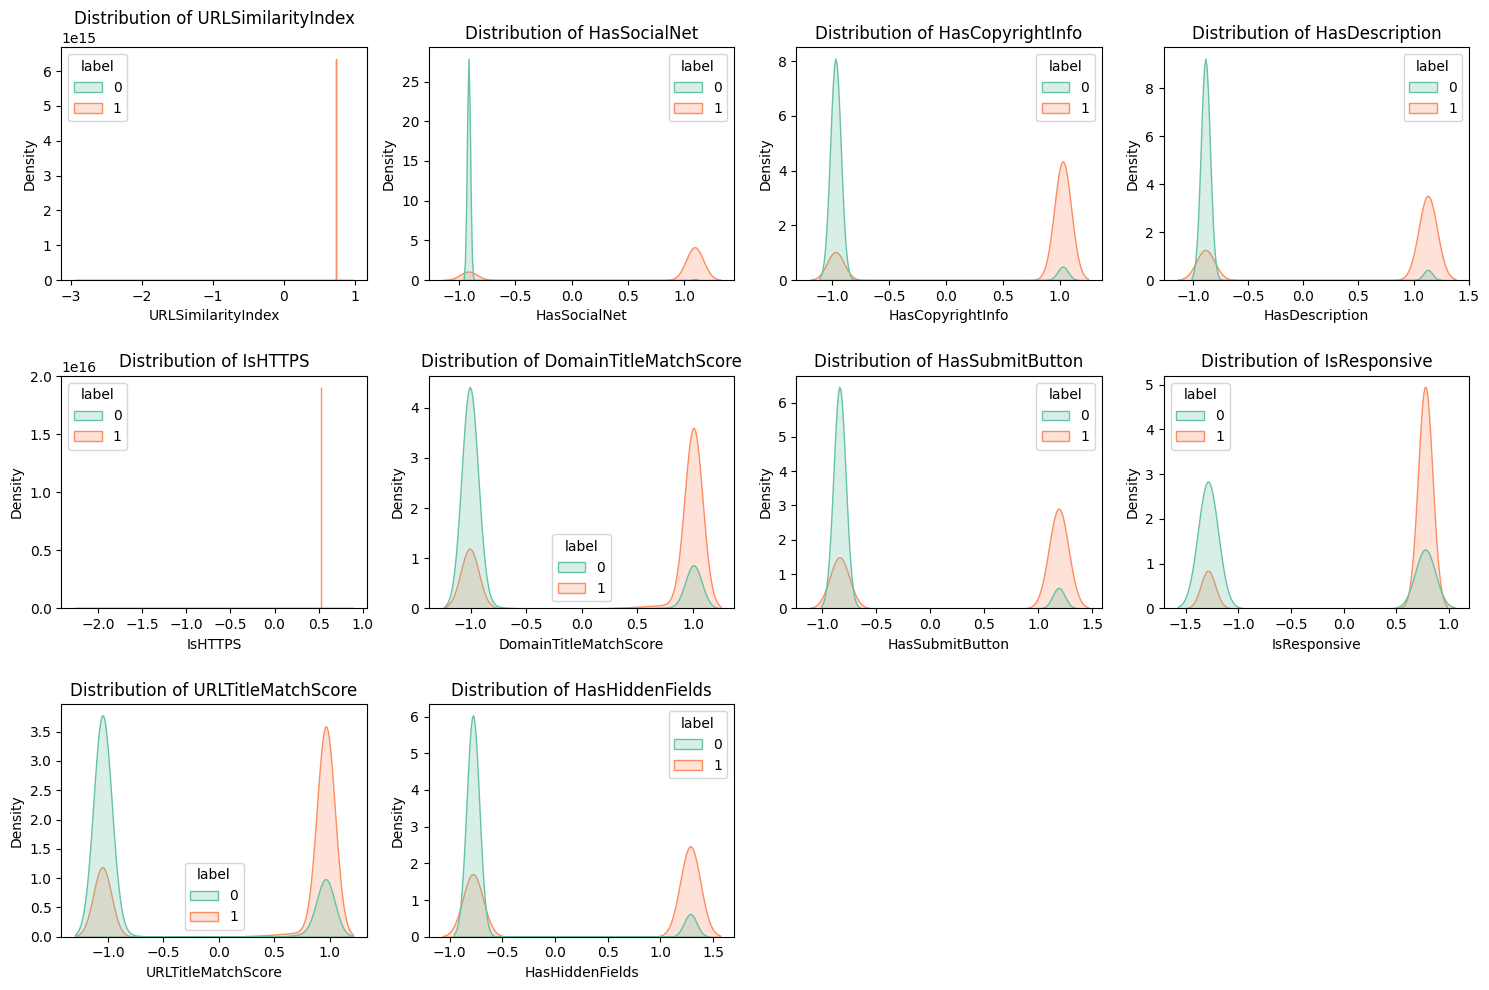

In [ ]:
# Select top numerical features most correlated with the target
top_features = target_corr.index[1:11]  # skip 'label'
plt.figure(figsize=(15, 10))

for i, col in enumerate(top_features, 1):
    plt.subplot(3, 4, i)
    sns.kdeplot(data=df, x=col, hue='label', fill=True, common_norm=False, palette='Set2')
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

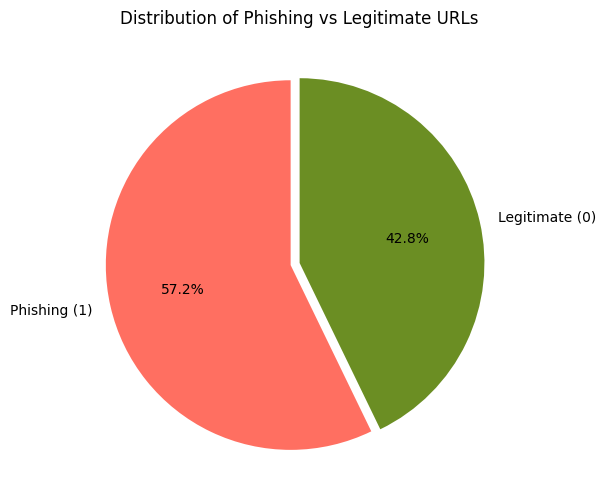

In [ ]:
label_counts = df['label'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(label_counts, labels=['Phishing (1)', 'Legitimate (0)'], autopct='%1.1f%%',
        colors=['#FF6F61', '#6B8E23'], startangle=90, explode=(0.05, 0))
plt.title('Distribution of Phishing vs Legitimate URLs')
plt.show()

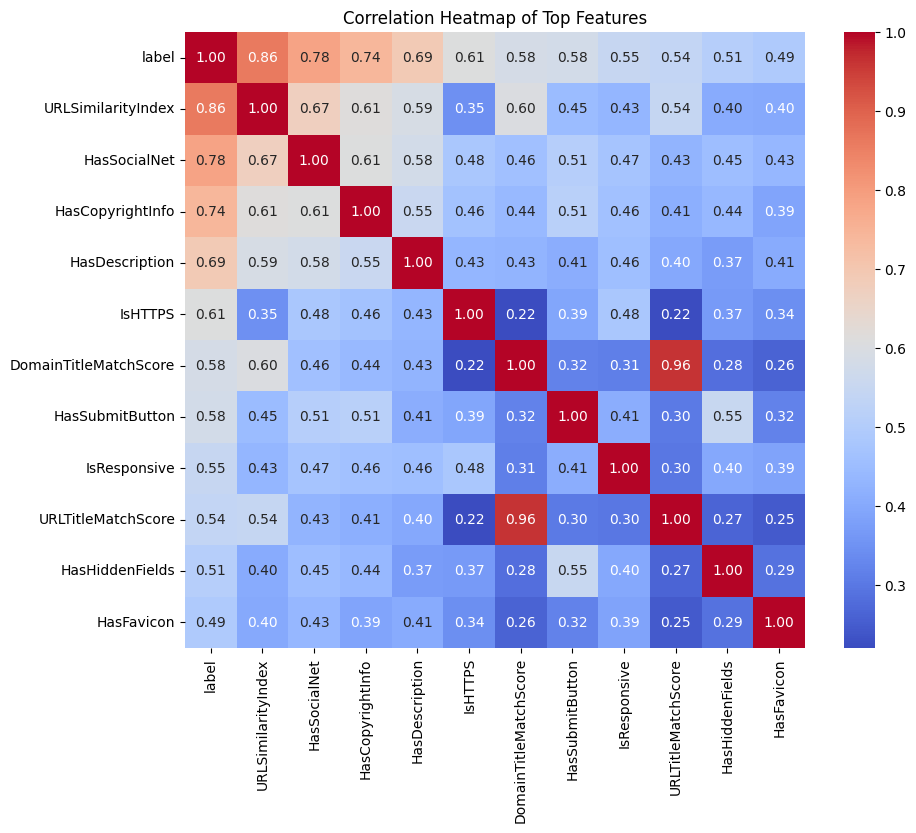

In [ ]:
top_corr_features = target_corr.index[:12]  # label + top 11 correlated
plt.figure(figsize=(10, 8))
sns.heatmap(df[top_corr_features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Top Features")
plt.show()


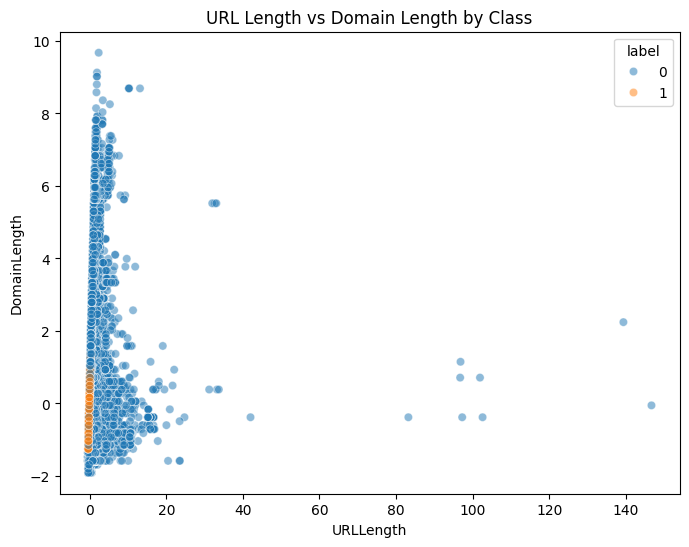

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='URLLength', y='DomainLength', hue='label', alpha=0.5)
plt.title('URL Length vs Domain Length by Class')
plt.show()

In [ ]:
x_train.shape

(188636, 1000)

In [ ]:
x_train[11]

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 3 stored elements and shape (1, 1000)>

In [ ]:
row_dense = x_train[11].toarray()  # Convert sparse row to dense NumPy array
print(row_dense.shape)  # (1, 1000)
print(row_dense)


(1, 1000)
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 

## Define hyperparameters: Define the range of hyperparameters to tune for the Logistic Regression model.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid for Logistic Regression
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100] # Inverse of regularization strength
}

GridSearchCV: Set up `GridSearchCV` with the Logistic Regression model and the defined hyperparameter grid.

In [ ]:
# Initialize the GridSearchCV object
grid_search = GridSearchCV(estimator=l_model, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)

Train with GridSearchCV**: Train the model using `GridSearchCV` on the training data.

In [ ]:
# Fit GridSearchCV to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(), n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100]},
             scoring='accuracy')

**4. Evaluate best model**: Evaluate the performance of the best model found by `GridSearchCV` on the test set.

In [ ]:
# Get the best model from GridSearchCV
best_model = grid_search.best_estimator_

# Evaluate the best model on the test set
y_pred_best = best_model.predict(x_test)

# Calculate evaluation metrics for the best model
accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)
conf_matrix_best = confusion_matrix(y_test, y_pred_best)

print(f"Best Model Accuracy on Test Set: {accuracy_best:.4f}")
print(f"Best Model Precision on Test Set: {precision_best:.4f}")
print(f"Best Model Recall on Test Set: {recall_best:.4f}")
print(f"Best Model F1-score on Test Set: {f1_best:.4f}")
print("\nConfusion Matrix for Best Model:")
print(conf_matrix_best)

Best Model Accuracy on Test Set: 0.9948
Best Model Precision on Test Set: 0.9918
Best Model Recall on Test Set: 0.9992
Best Model F1-score on Test Set: 0.9955

Confusion Matrix for Best Model:
[[19965   224]
 [   22 26948]]


Report best parameters: Display the best hyperparameters found by `GridSearchCV`.

In [ ]:
# Print the best hyperparameters found
print("Best hyperparameters:", grid_search.best_params_)

Best hyperparameters: {'C': 100}


# Prediction system

In [ ]:

def preprocess_url(url, tokenizer, stemmer, vectorizer):
    tokens = tokenizer.tokenize(url)
    stemmed_tokens = [stemmer.stem(word) for word in tokens]
    text = ' '.join(stemmed_tokens)
    features = vectorizer.transform([text])
    return features


input_url = "https://www.voicefmradio.co.uk"


if 'tokenizer' not in globals() or 'stemmer' not in globals() or 'cv' not in globals():
    print("Error: tokenizer, stemmer, or cv is not defined. Please run the preprocessing cells.")
else:
    input_features = preprocess_url(input_url, tokenizer, stemmer, cv)

    # Use the best_model (from GridSearchCV) for prediction
    # Ensure best_model is defined from the GridSearchCV step
    if 'best_model' not in globals():
        print("Error: best_model is not defined. Please run the GridSearchCV cells.")
    else:
        # Make the prediction
        pred = best_model.predict(input_features)

        # Output result
        if pred[0] == 1:
            print(f"The URL '{input_url}' is predicted as: Phishing")
        else:
            print(f"The URL '{input_url}' is predicted as: Not phishing")

The URL 'https://www.voicefmradio.co.uk' is predicted as: Phishing


In [ ]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('vectorizer', cv),
    ('classifier', best_model)
])

pickle.dump(pipeline, open("phishing_pipeline.pkl", "wb"))


In [ ]:
import sklearn

print(sklearn.__version__)

1.6.1
